# 01 - Data acquisition and exploratory data analysis
**Dataset:** UCI Heart Disease, Cleveland subset (`processed.cleveland.data`, UCI id 45).  
**Goal of this notebook:** acquire the data reproducibly, validate it, clean it, and explore it with histograms, a correlation heatmap and class-balance plots. All numbers below are computed from the file, nothing is typed by hand.

> Academic exercise - not a clinically validated diagnostic tool.

In [1]:
# Make the repository's src/ importable whether or not `pip install -e .` was run
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import os; os.chdir(ROOT)
import platform, socket, datetime
print("Run on host:", socket.gethostname(), "| Python", platform.python_version(),
      "| started", datetime.datetime.now().isoformat(timespec="seconds"))

Run on host: ip-10-3-24-59.ap-south-1.compute.internal | Python 3.12.9 | started 2026-10-16T20:04:45


## 1. Acquire the data (download script, checksum recorded in `data/raw/manifest.json`)

In [2]:
import subprocess, json
subprocess.run([sys.executable, 'scripts/download_data.py'], check=True)  # raises if acquisition fails
print(json.dumps(json.load(open('data/raw/manifest.json')), indent=2))

[download] data/raw/processed.cleveland.data already present, SHA-256 verified (a74b7efa387b...)
{
  "dataset": "UCI Heart Disease - Cleveland (processed.cleveland.data)",
  "uci_dataset_id": 45,
  "source_url": "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data",
  "landing_page": "https://archive.ics.uci.edu/dataset/45/heart+disease",
  "license": "CC BY 4.0",
  "sha256": "a74b7efa387bc9d108d7d0115d831fe9b414b29ae7124f331b622b4efa0427c8",
  "bytes": 18461,
  "rows": 303,
  "columns": 14,
  "downloaded_at_utc": "2026-10-16T14:29:15+00:00"
}


## 2. Load the raw file and inspect it
The file has no header; `?` marks missing values.

In [3]:
from heartrisk.data import load_raw, clean
from heartrisk.schema import FEATURES, NUMERIC_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES
raw = load_raw()
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


In [5]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.44,9.04,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.68,0.47,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.16,0.96,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.69,17.60,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.69,51.78,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.15,0.36,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.99,0.99,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.61,22.88,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.33,0.47,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.04,1.16,0.0,0.0,0.8,1.6,6.2


## 3. Data quality: missing values, duplicates, invalid codes

In [6]:
print('Missing values per column:')
print(raw.isna().sum()[raw.isna().sum() > 0])
print('Rows with any missing value:', int(raw.isna().any(axis=1).sum()))
print('Exact duplicate rows:', int(raw.duplicated().sum()))
from heartrisk.data import invalid_value_mask
print('Rows with out-of-range values / undefined codes:', int(invalid_value_mask(raw).sum()))

Missing values per column:
ca      4
thal    2
dtype: int64
Rows with any missing value: 6
Exact duplicate rows: 0
Rows with out-of-range values / undefined codes: 0


## 4. Clean
* `?` -> missing (kept as NaN; **imputed inside the model pipeline**, fitted on training folds only, to avoid leakage)
* exact duplicates removed, rows with impossible values removed
* target: original `num` (0-4) -> binary `target` (0 = absent, 1 = present)

In [7]:
df, report = clean(raw)
import json; print(json.dumps(report.to_dict(), indent=2))
df.to_csv('data/processed/heart_clean.csv', index=False)
print('saved data/processed/heart_clean.csv', df.shape)

{
  "rows_raw": 303,
  "rows_clean": 303,
  "duplicates_removed": 0,
  "invalid_rows_removed": 0,
  "missing_by_column": {
    "ca": 4,
    "thal": 2
  },
  "rows_with_missing": 6,
  "target_counts": {
    "0": 164,
    "1": 139
  },
  "raw_num_counts": {
    "0": 164,
    "1": 55,
    "2": 36,
    "3": 35,
    "4": 13
  }
}
saved data/processed/heart_clean.csv (303, 14)


### Feature types used by the pipeline

In [8]:
import pandas as pd
pd.DataFrame({'feature': NUMERIC_FEATURES + BINARY_FEATURES + CATEGORICAL_FEATURES,
              'type': ['numeric (median impute + standard scale)']*len(NUMERIC_FEATURES)
                    + ['binary (mode impute)']*len(BINARY_FEATURES)
                    + ['categorical (mode impute + one-hot)']*len(CATEGORICAL_FEATURES)})

,feature,type
0,age,numeric (median impute + standard scale)
1,trestbps,numeric (median impute + standard scale)
2,chol,numeric (median impute + standard scale)
3,thalach,numeric (median impute + standard scale)
4,oldpeak,numeric (median impute + standard scale)
5,ca,numeric (median impute + standard scale)
6,sex,binary (mode impute)
7,fbs,binary (mode impute)
8,exang,binary (mode impute)
9,cp,categorical (mode impute + one-hot)


## 5. Visual EDA
Figures are written to `reports/figures/eda/` and used in the report.

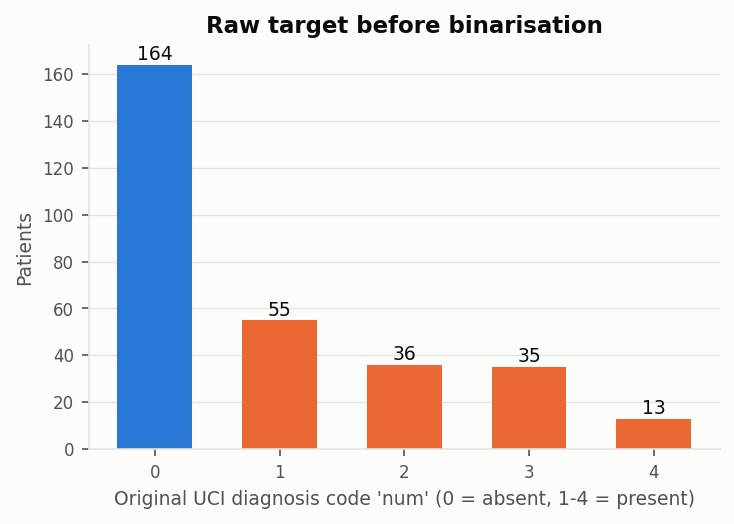

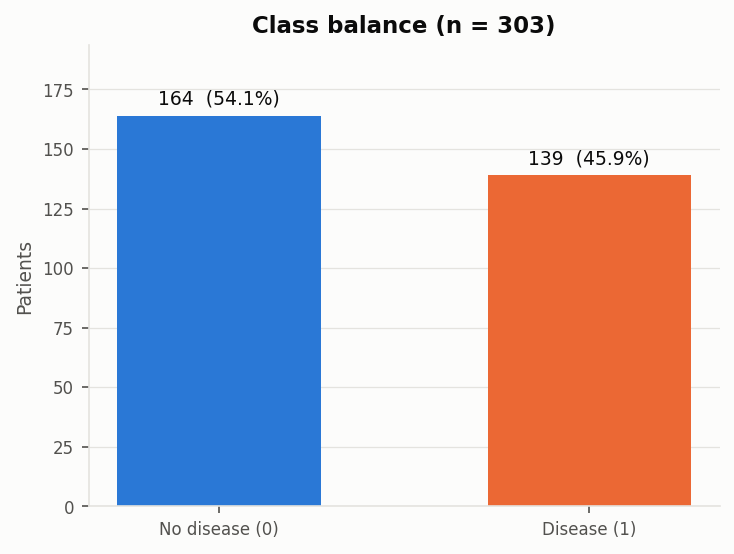

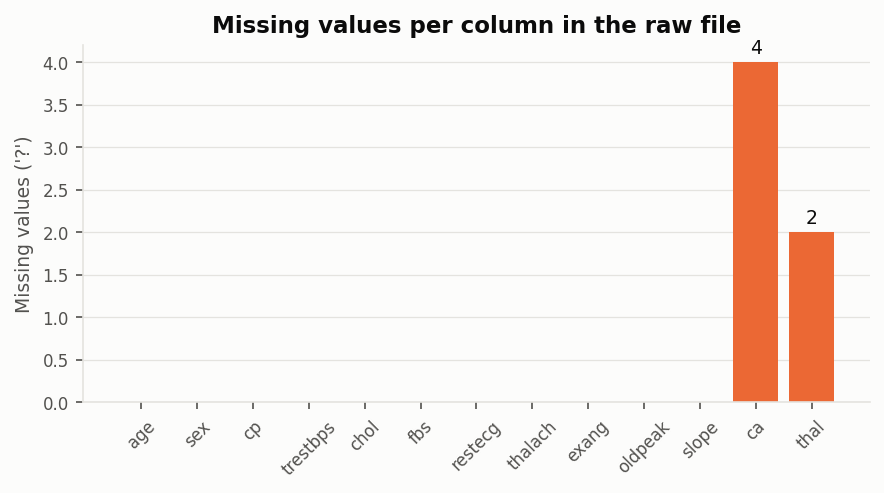

In [9]:
from heartrisk import eda
summary = eda.run()
from IPython.display import Image, display
for f in ['raw_target_num', 'class_balance', 'missing_values']:
    display(Image(f'reports/figures/eda/{f}.png'))

### Histograms of numeric features by class

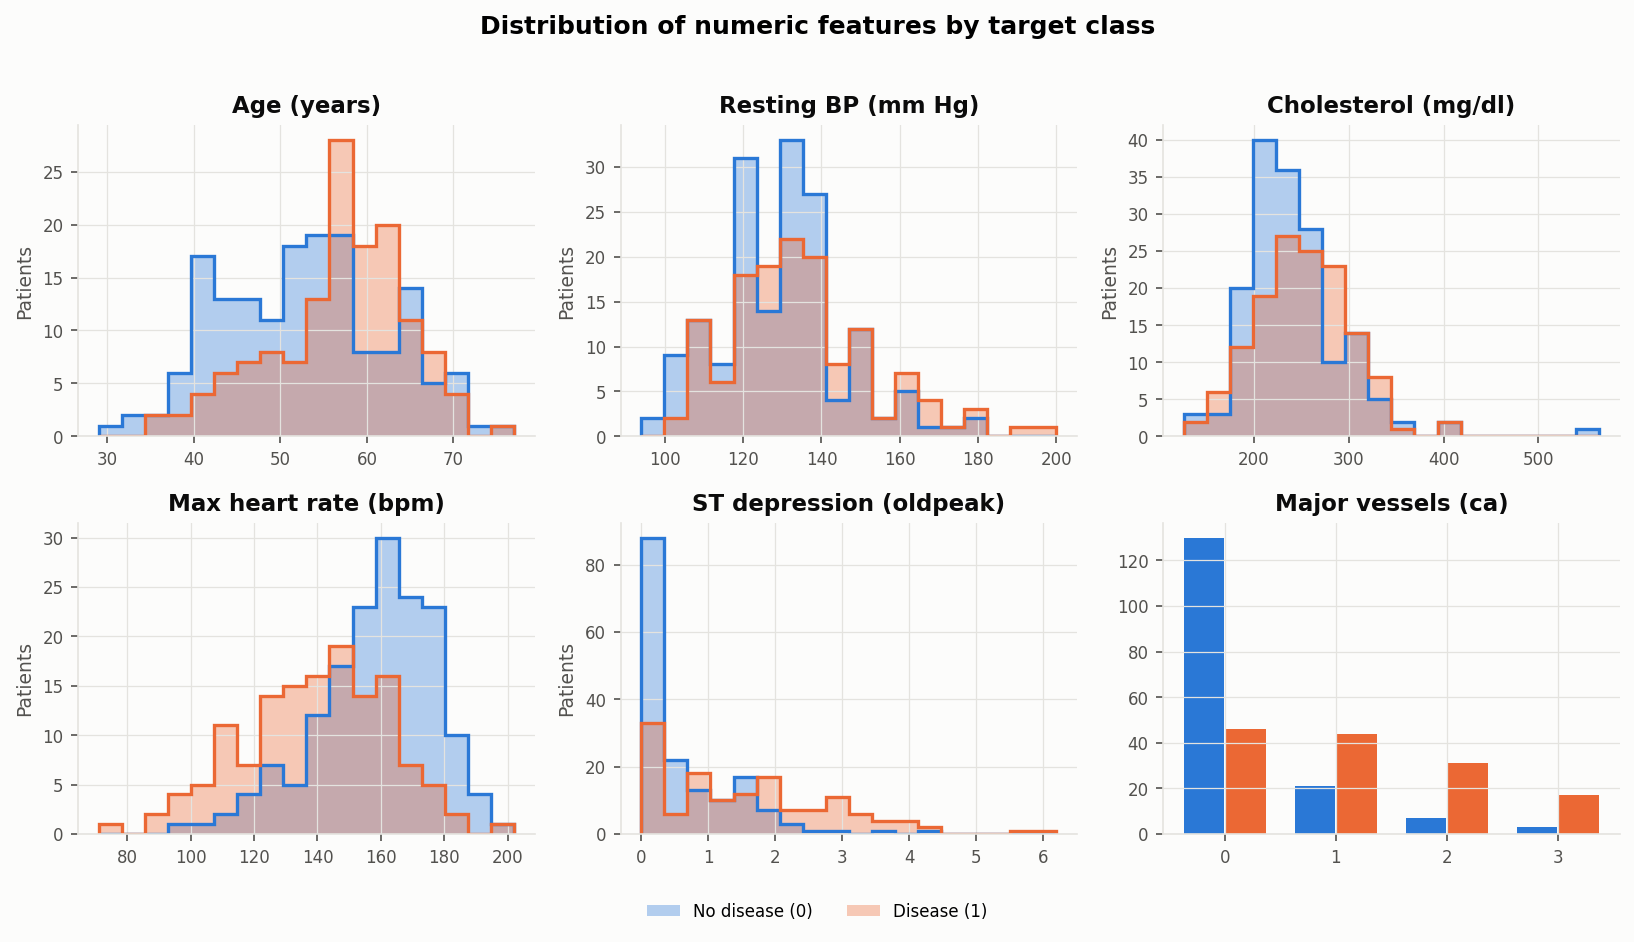

In [10]:
display(Image('reports/figures/eda/numeric_histograms.png'))

### Disease rate by categorical / binary feature

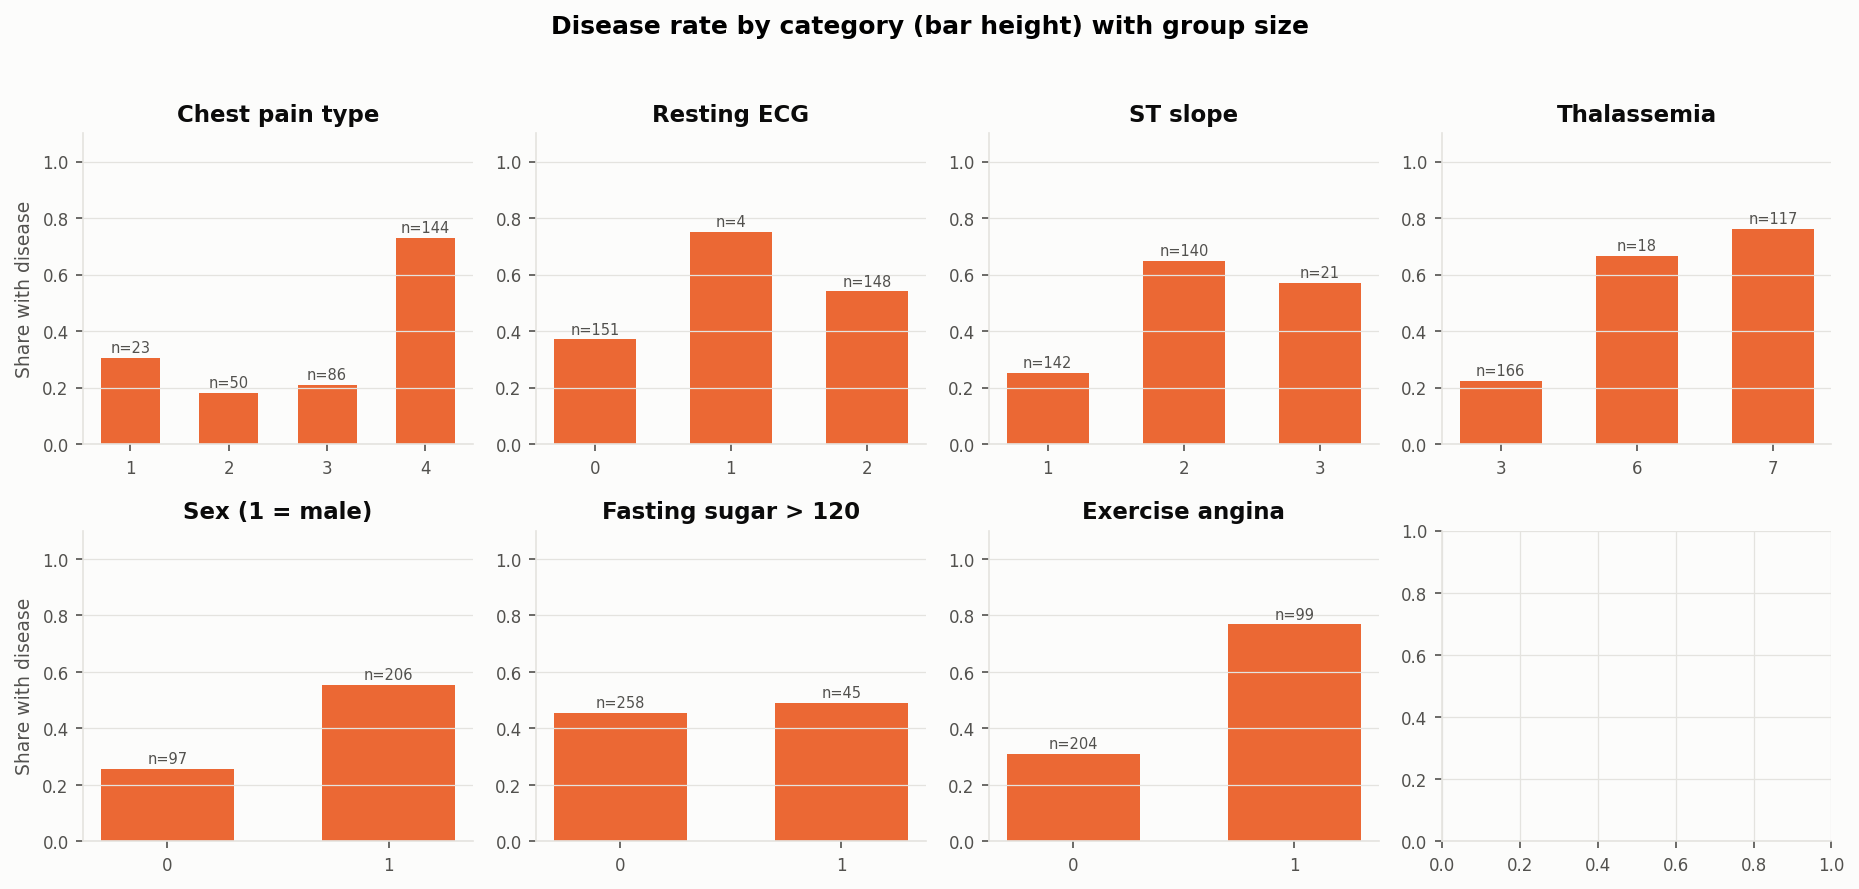

In [11]:
display(Image('reports/figures/eda/categorical_disease_rate.png'))

### Correlation heatmap

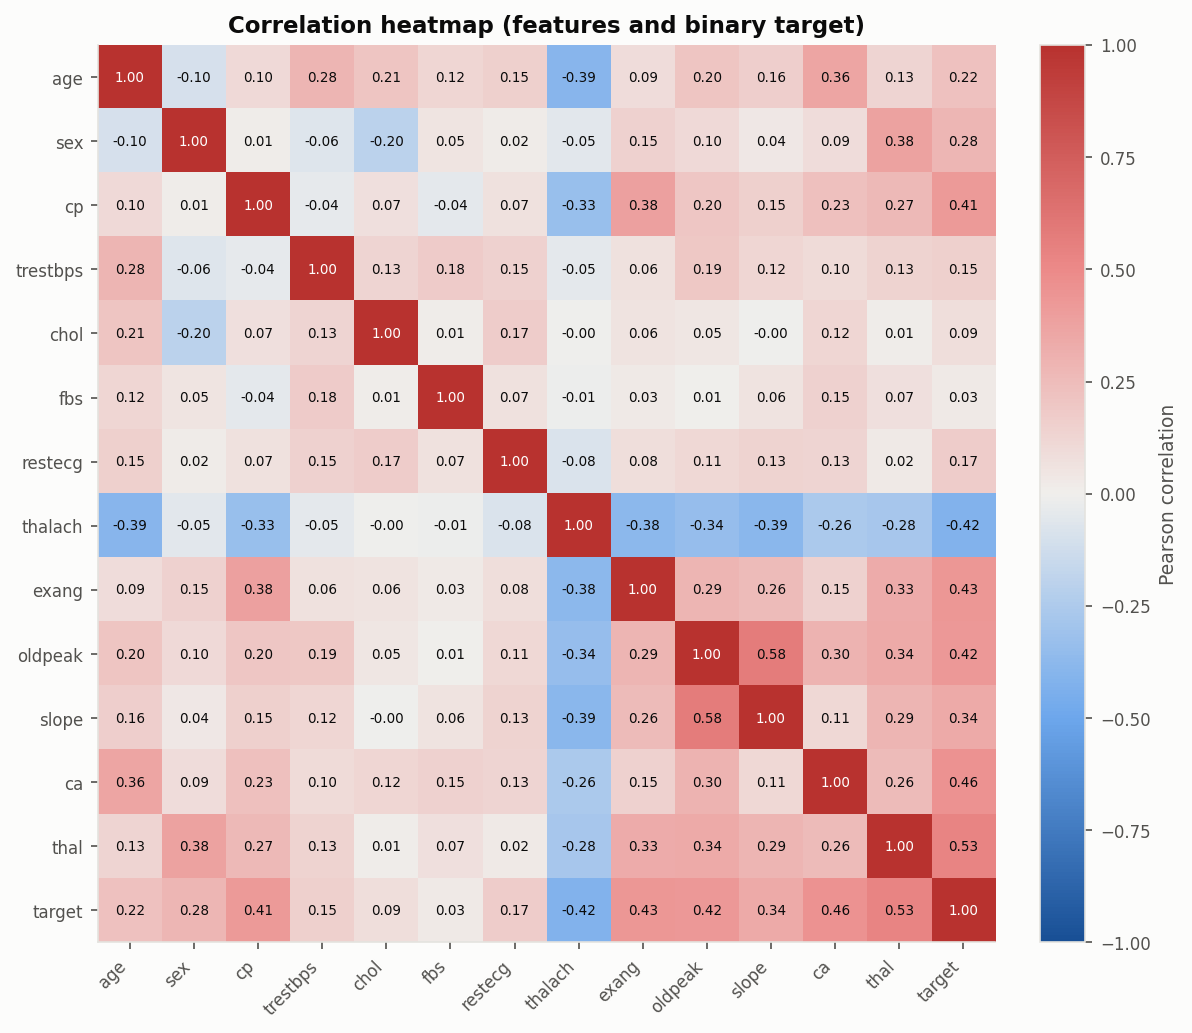

In [12]:
display(Image('reports/figures/eda/correlation_heatmap.png'))

## 6. Observations (generated from the data)

In [13]:
t = summary['target_counts']; n = summary['rows_clean']
print(f"Clean dataset: {n} patients, {summary['n_features']} features.")
print(f"Class balance: {t['0']} without disease ({t['0']/n:.1%}), {t['1']} with disease ({t['1']/n:.1%}) "
      f"-> {'roughly balanced; accuracy is meaningful but ROC-AUC/recall are also reported' if 0.4 <= t['1']/n <= 0.6 else 'imbalanced; rely on ROC-AUC, precision and recall'}.")
print("Missing values in raw file:", summary['missing_raw'])
print("\nStrongest linear associations with the target (Pearson r):")
for k, v in list(summary['corr_with_target_sorted'].items())[:6]:
    print(f"  {k:9s} {v:+.3f}")
print("\nMean of numeric features by class:")
print(pd.DataFrame(summary['numeric_mean_by_class']).T)

Clean dataset: 303 patients, 13 features.
Class balance: 164 without disease (54.1%), 139 with disease (45.9%) -> roughly balanced; accuracy is meaningful but ROC-AUC/recall are also reported.
Missing values in raw file: {'ca': 4, 'thal': 2}

Strongest linear associations with the target (Pearson r):
  thal      +0.526
  ca        +0.460
  exang     +0.432
  oldpeak   +0.425
  thalach   -0.417
  cp        +0.414

Mean of numeric features by class:
               0       1
age        52.59   56.63
trestbps  129.25  134.57
chol      242.64  251.47
thalach   158.38  139.26
oldpeak     0.59    1.57
ca          0.27    1.14


**Leakage check:** the only target-derived column is `num`, which is converted into `target` and then dropped; no other feature is computed from the diagnosis. Scaling, imputation and encoding are fitted inside the scikit-learn pipeline during cross-validation.